In [4]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import pyogrio
import yaml

ROOT = Path("..")
AQ_DIR = ROOT / "data" / "raw" / "aqueduct" / "Aqueduct40_waterrisk_download_Y2023M07D05"
GDB = AQ_DIR / "GDB" / "Aq40_Y2023D07M05.gdb"
CSV_DIR = AQ_DIR / "CVS"          # (sic) the folder name in the WRI download
INTERIM = ROOT / "data" / "interim"

with open(ROOT / "config.yaml") as f:
    config = yaml.safe_load(f)

print("GDB exists:", GDB.exists())
print("CSV files:", [p.name for p in CSV_DIR.glob("*.csv")])

GDB exists: True
CSV files: ['Aqueduct40_future_annual_y2023m07d05.csv', 'Aqueduct40_baseline_annual_y2023m07d05.csv', 'Aqueduct40_baseline_monthly_y2023m07d05.csv']


In [5]:
for layer_name, geom_type in pyogrio.list_layers(GDB):
    info = pyogrio.read_info(GDB, layer=layer_name)
    print(f"{layer_name}: {geom_type} | {info['features']:,} rows | {len(info['fields'])} columns")

baseline_annual: MultiPolygon | 68,506 rows | 236 columns
baseline_monthly: MultiPolygon | 16,395 rows | 149 columns
future_annual: MultiPolygon | 16,395 rows | 186 columns


In [6]:
for layer_name, _ in pyogrio.list_layers(GDB):
    fields = pyogrio.read_info(GDB, layer=layer_name)["fields"]
    print(f"\n{layer_name} ({len(fields)} columns):")
    print(list(fields[:25]), "..." if len(fields) > 25 else "")


baseline_annual (236 columns):
['string_id', 'aq30_id', 'Shape_Leng', 'string_id_1', 'aq30_id_1', 'pfaf_id', 'gid_1', 'aqid', 'gid_0', 'name_0', 'name_1', 'area_km2', 'bws_raw', 'bws_score', 'bws_cat', 'bws_label', 'bwd_raw', 'bwd_score', 'bwd_cat', 'bwd_label', 'iav_raw', 'iav_score', 'iav_cat', 'iav_label', 'sev_raw'] ...

baseline_monthly (149 columns):
['fid_1', 'pfaf_id', 'pfaf_id_1', 'bws_01_raw', 'bws_01_score', 'bws_01_cat', 'bws_01_label', 'bwd_01_raw', 'bwd_01_score', 'bwd_01_cat', 'bwd_01_label', 'iav_01_raw', 'iav_01_score', 'iav_01_cat', 'iav_01_label', 'bws_02_raw', 'bws_02_score', 'bws_02_cat', 'bws_02_label', 'bwd_02_raw', 'bwd_02_score', 'bwd_02_cat', 'bwd_02_label', 'iav_02_raw', 'iav_02_score'] ...

future_annual (186 columns):
['fid_1', 'pfaf_id', 'fid', 'pfaf_id_1', 'bau30_ba_x_r', 'bau30_ba_x_l', 'bau50_ba_x_r', 'bau50_ba_x_l', 'bau80_ba_x_r', 'bau80_ba_x_l', 'opt30_ba_x_r', 'opt30_ba_x_l', 'opt50_ba_x_r', 'opt50_ba_x_l', 'opt80_ba_x_r', 'opt80_ba_x_l', 'pes30_ba

In [7]:
b = config["scope"]["bbox"]
BBOX = (b["west"], b["south"], b["east"], b["north"])   # (minx, miny, maxx, maxy)

# Future water stress columns: e.g. bau50_ws_x_s (score), bau50_ws_x_c (category)
fut_fields = list(pyogrio.read_info(GDB, layer="future_annual")["fields"])
fut_cols = [f"{s}{y}_ws_x_{t}"
            for s in config["aqueduct"]["scenarios"]
            for y in config["aqueduct"]["years"]
            for t in ("r", "s", "c", "l")]
print("Not found:", [c for c in fut_cols if c not in fut_fields] or "none")
fut_cols = [c for c in fut_cols if c in fut_fields]

basins = gpd.read_file(GDB, layer="future_annual", columns=["pfaf_id"] + fut_cols,
                       bbox=BBOX, engine="pyogrio")
print(len(basins), "basins in the Europe bounding box |", basins.crs)

Not found: none
1269 basins in the Europe bounding box | EPSG:4326


/Users/carolinasoriano/anaconda3/envs/ia-agua/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


In [8]:
base = pyogrio.read_dataframe(GDB, layer="baseline_annual",
                              columns=["pfaf_id", "bws_raw", "bws_score", "bws_cat", "bws_label"],
                              read_geometry=False)
base = base[base["pfaf_id"].isin(basins["pfaf_id"])]

# Check: is water stress identical for all pieces of the same basin?
n_values = base.groupby("pfaf_id")[["bws_score", "bws_cat"]].nunique()
print("Basins with more than one value:", (n_values > 1).any(axis=1).sum())

base = base.drop_duplicates("pfaf_id")
print(len(base), "basins with baseline values")

Basins with more than one value: 0
1269 basins with baseline values


In [9]:
SUMMER = ["06", "07", "08"]   # June, July, August
mcols = [f"bws_{m}_{t}" for m in SUMMER for t in ("raw", "score")]

monthly = pyogrio.read_dataframe(GDB, layer="baseline_monthly",
                                 columns=["pfaf_id"] + mcols, read_geometry=False)
monthly = monthly[monthly["pfaf_id"].isin(basins["pfaf_id"])].drop_duplicates("pfaf_id")

# Summer peak = the worst of the three summer months
monthly["bws_summer_raw"] = monthly[[f"bws_{m}_raw" for m in SUMMER]].max(axis=1)
monthly["bws_summer_score"] = monthly[[f"bws_{m}_score" for m in SUMMER]].max(axis=1)
monthly = monthly[["pfaf_id", "bws_summer_raw", "bws_summer_score"]]
print(len(monthly), "basins with summer values")

1269 basins with summer values


In [10]:
basins_eu = (
    basins
    .merge(base, on="pfaf_id", how="left")
    .merge(monthly, on="pfaf_id", how="left")
)
print(len(basins_eu), "basins |", basins_eu.shape[1], "columns")
basins_eu.head(3)

1269 basins | 32 columns


,pfaf_id,bau30_ws_x_r,bau30_ws_x_s,bau30_ws_x_c,bau30_ws_x_l,bau50_ws_x_r,bau50_ws_x_s,bau50_ws_x_c,bau50_ws_x_l,opt30_ws_x_r,...,pes50_ws_x_s,pes50_ws_x_c,pes50_ws_x_l,geometry,bws_raw,bws_score,bws_cat,bws_label,bws_summer_raw,bws_summer_score
0,211017.0,2.685542,5.000000,4.0,Extremely high (>80%),5.047078,5.000000,4.0,Extremely high (>80%),3.811382,...,5.000000,4.0,Extremely high (>80%),"MULTIPOLYGON (((35.86111 34.85, 35.85355 34.85...",2.404679,5.000000,4.0,Extremely High (>80%),4.838747,5.000000
1,211018.0,1.470636,4.878369,4.0,Extremely high (>80%),2.321370,5.000000,4.0,Extremely high (>80%),1.890135,...,5.000000,4.0,Extremely high (>80%),"MULTIPOLYGON (((36.34583 34.88333, 36.34341 34...",1.684768,5.000000,4.0,Extremely High (>80%),2.462546,5.000000
2,211019.0,0.465282,3.218105,3.0,High (40-80%),0.638560,3.674823,3.0,High (40-80%),0.552899,...,3.752204,3.0,High (40-80%),"MULTIPOLYGON (((36.46667 36.94583, 36.4714 36....",0.535084,3.419767,3.0,High (40-80%),0.835542,4.062712


In [11]:
# 1. Which water stress categories exist today?
print(basins_eu[["bws_cat", "bws_label"]].value_counts().sort_index(), "\n")

# 2. Negative values in score columns usually mean "no data" or a special case
score_cols = [c for c in basins_eu.columns if c.endswith("_score") or c.endswith("_x_s")]
print("Negative values per score column:")
print((basins_eu[score_cols] < 0).sum())

bws_cat  bws_label             
-9999.0  No Data                    31
-1.0     Arid and Low Water Use     21
 0.0     Low (<10%)                697
 1.0     Low - Medium (10-20%)     145
 2.0     Medium - High (20-40%)    137
 3.0     High (40-80%)             103
 4.0     Extremely High (>80%)     135
Name: count, dtype: int64 

Negative values per score column:
bau30_ws_x_s         0
bau50_ws_x_s         0
opt30_ws_x_s         0
opt50_ws_x_s         0
pes30_ws_x_s         0
pes50_ws_x_s         0
bws_score           31
bws_summer_score     0
dtype: int64


In [12]:
import numpy as np

NO_DATA = -9999

# 1. "No data" -> NaN (empty) in every numeric column
num_cols = basins_eu.select_dtypes("number").columns.drop("pfaf_id")
basins_eu[num_cols] = basins_eu[num_cols].mask(basins_eu[num_cols] == NO_DATA, np.nan)

# 2. Flag arid & low water use basins instead of treating -1 as a normal category
basins_eu["bws_arid_low_use"] = basins_eu["bws_cat"] == -1

print("No-data basins (bws_score is NaN):", basins_eu["bws_score"].isna().sum())
print("Arid & low water use basins:", basins_eu["bws_arid_low_use"].sum())
print("\nbws_score of arid basins:")
print(basins_eu.loc[basins_eu["bws_arid_low_use"], "bws_score"].describe())

No-data basins (bws_score is NaN): 31
Arid & low water use basins: 21

bws_score of arid basins:
count    21.0
mean      5.0
std       0.0
min       5.0
25%       5.0
50%       5.0
75%       5.0
max       5.0
Name: bws_score, dtype: float64


Matplotlib is building the font cache; this may take a moment.


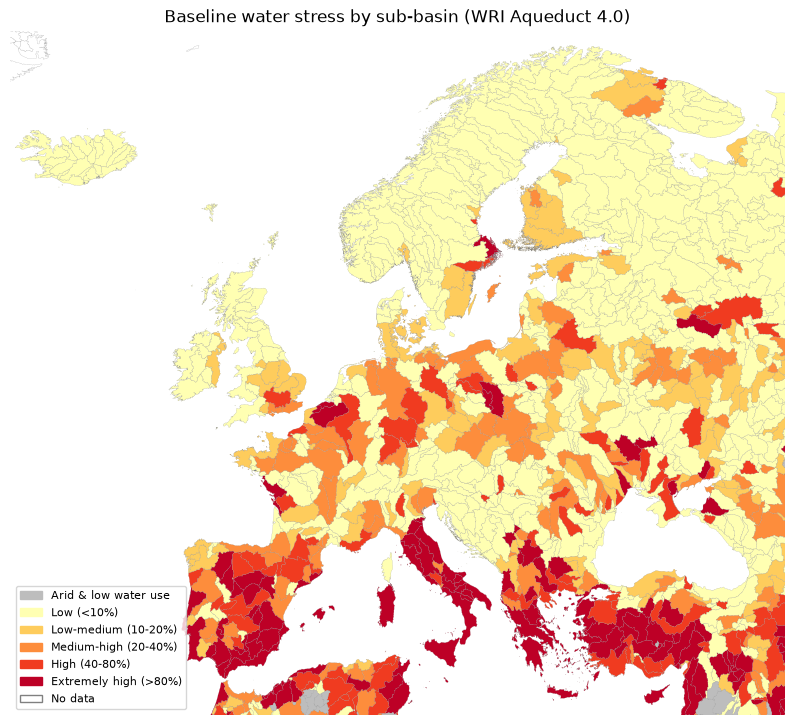

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CAT_STYLE = {
    -1: ("Arid & low water use", "#bdbdbd"),
    0: ("Low (<10%)", "#ffffb2"),
    1: ("Low-medium (10-20%)", "#fecc5c"),
    2: ("Medium-high (20-40%)", "#fd8d3c"),
    3: ("High (40-80%)", "#f03b20"),
    4: ("Extremely high (>80%)", "#bd0026"),
}
colors = basins_eu["bws_cat"].map({k: v[1] for k, v in CAT_STYLE.items()}).fillna("white")

fig, ax = plt.subplots(figsize=(10, 10))
basins_eu.plot(ax=ax, color=colors, edgecolor="grey", linewidth=0.1)
ax.set_xlim(b["west"], b["east"])
ax.set_ylim(b["south"], b["north"])
handles = [Patch(color=c, label=l) for l, c in CAT_STYLE.values()]
handles.append(Patch(facecolor="white", edgecolor="grey", label="No data"))
ax.legend(handles=handles, loc="lower left", fontsize=8)
ax.set_title("Baseline water stress by sub-basin (WRI Aqueduct 4.0)")
ax.set_axis_off()

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "aqueduct_baseline_water_stress.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
basins_eu.to_parquet(INTERIM / "aqueduct_europe.parquet")

check = gpd.read_parquet(INTERIM / "aqueduct_europe.parquet")
print(len(check), "basins saved |", check.crs, "|", check.shape[1], "columns")

1269 basins saved | {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, 

In [16]:
!git add -A
!git commit -m "Step 2: Aqueduct 4.0 water stress for European basins"
!git push

[main 98082cc] Step 2: Aqueduct 4.0 water stress for European basins
 3 files changed, 1976 insertions(+), 88 deletions(-)
 create mode 100644 ia-agua-datacenters/figures/aqueduct_baseline_water_stress.png
 create mode 100644 ia-agua-datacenters/notebooks/02_aqueduct.ipynb
Enumerating objects: 12, done.
Counting objects: 100% (12/12), done.
Delta compression using up to 8 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 1018.30 KiB | 29.95 MiB/s, done.
Total 8 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (3/3), completed with 2 local objects.
To https://github.com/Carol-Sust/Sustainability.git
   156124d..98082cc  main -> main
